Kenneth Heisler

In [3]:
#Import useful libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from pandas.plotting import scatter_matrix
#import pingouin as pg
import statsmodels.api as sm


In [4]:
#Troublesome Libraries
#from geopy.geocoders import Nominatim
#import folium
#from geopy.extra.rate_limiter import RateLimiter
#from googleapiclient.discovery import build
#import googlemaps


In [5]:
# Read in the csv file
df = pd.read_csv("social_capital_county.csv")

In [6]:
#Basic Data Exploration 
df.head()
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3089 entries, 0 to 3088
Data columns (total 26 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   county                        3089 non-null   int64  
 1   county_name                   3089 non-null   object 
 2   num_below_p50                 3087 non-null   float64
 3   pop2018                       2983 non-null   float64
 4   ec_county                     3018 non-null   float64
 5   ec_se_county                  3018 non-null   float64
 6   child_ec_county               2729 non-null   float64
 7   child_ec_se_county            2729 non-null   float64
 8   ec_grp_mem_county             3012 non-null   float64
 9   ec_high_county                3018 non-null   float64
 10  ec_high_se_county             3018 non-null   float64
 11  child_high_ec_county          2729 non-null   float64
 12  child_high_ec_se_county       2729 non-null   float64
 13  ec_

,county,num_below_p50,pop2018,ec_county,ec_se_county,child_ec_county,child_ec_se_county,ec_grp_mem_county,ec_high_county,ec_high_se_county,...,child_exposure_county,child_high_exposure_county,bias_grp_mem_county,bias_grp_mem_high_county,child_bias_county,child_high_bias_county,clustering_county,support_ratio_county,volunteering_rate_county,civic_organizations_county
count,3089.000000,3.087000e+03,2.983000e+03,3018.000000,3018.000000,2729.000000,2729.000000,3012.000000,3018.000000,3018.000000,...,2729.000000,2729.000000,3012.000000,3012.000000,2729.000000,2729.000000,3089.000000,3089.000000,3089.000000,3089.000000
mean,30218.783101,1.059956e+04,1.080104e+05,0.814464,0.013409,0.825335,0.032464,0.850302,1.252636,0.014754,...,0.827984,0.885009,0.064161,-0.187968,0.001222,-0.085386,0.116456,0.988901,0.078068,0.019762
std,15138.796297,4.164424e+04,3.377826e+05,0.177126,0.006176,0.221210,0.013225,0.213428,0.176560,0.006231,...,0.226322,0.248020,0.050633,0.064644,0.033337,0.048938,0.020364,0.015467,0.034841,0.009850
min,1001.000000,5.230174e+01,5.440000e+02,0.294690,0.004360,0.221880,0.011990,0.187420,0.700620,0.004750,...,0.216910,0.217280,-0.108090,-0.536180,-0.144020,-0.370950,0.071620,0.696760,0.009650,0.003490
25%,18161.000000,1.626969e+03,1.263000e+04,0.695607,0.009142,0.678750,0.022390,0.708260,1.134863,0.010060,...,0.673550,0.715310,0.030808,-0.221698,-0.018260,-0.111190,0.102690,0.986830,0.055280,0.014020
50%,29135.000000,3.353481e+03,2.788700e+04,0.806830,0.011900,0.815510,0.029900,0.840455,1.258200,0.013495,...,0.816630,0.868680,0.063970,-0.179075,0.001960,-0.079100,0.114570,0.993740,0.073280,0.017780
75%,45049.000000,7.326979e+03,7.272850e+04,0.936783,0.015800,0.962130,0.039900,0.996458,1.384345,0.017788,...,0.964820,1.040880,0.095450,-0.143335,0.019880,-0.052200,0.127240,0.996720,0.093960,0.023060
max,56045.000000,1.576718e+06,1.009805e+07,1.359700,0.050230,1.611360,0.091120,1.475880,1.715070,0.050990,...,1.634340,1.655150,0.334570,-0.043250,0.162700,0.069830,0.260970,1.000000,0.308736,0.195429


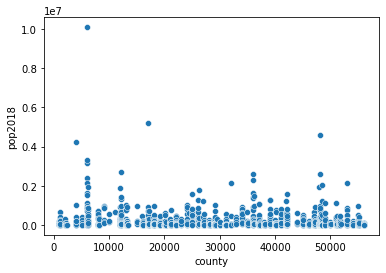

In [7]:
sns.scatterplot(x='county', y='pop2018', data=df)
plt.show()

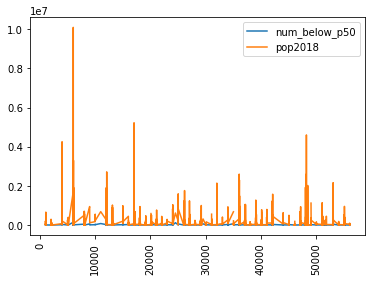

In [8]:
#Number of children with below-national-median parental household income compared to population 
y1 = df['num_below_p50']
y2 = df['pop2018']
x = df['county']
plt.plot(x, y1)
plt.plot(x, y2)
plt.legend(['num_below_p50', 'pop2018'])
plt.xticks(rotation=90)
plt.show()


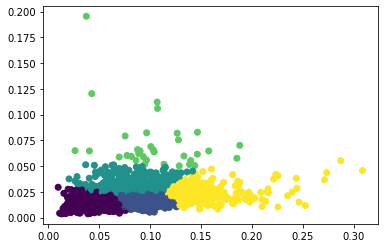

In [9]:
#Civic Engagement Statistics 
country_df = df[['volunteering_rate_county', 'civic_organizations_county']]
scaler = StandardScaler()
country_scaled = scaler.fit_transform(country_df)
#I determined 5 clusters seemed like appropriate number of clusters
n_clusters = 5
kmeans = KMeans(n_clusters=n_clusters)
kmeans.fit(country_scaled)
labels = kmeans.predict(country_scaled)
df['cluster'] = labels

plt.scatter(country_df['volunteering_rate_county'], country_df['civic_organizations_county'], c=labels)
plt.show()


In [10]:
#Failed Geocoding
#def geocode(place):
    #geolocator = Nominatim(user_agent="cics397a")
    #geocode = RateLimiter(geolocator.geocode, min_delay_seconds=1)
    #location = geolocator.geocode(place)
    #if location:
        #return location.latitude, location.longitude
    #else:
        #return None, None

#gmaps = googlemaps.Client(key='YOUR_API_KEY_HERE')


Massachusetts Analyses

In [11]:
df_MA = df[df['county_name'].str.contains('Massachusetts')]

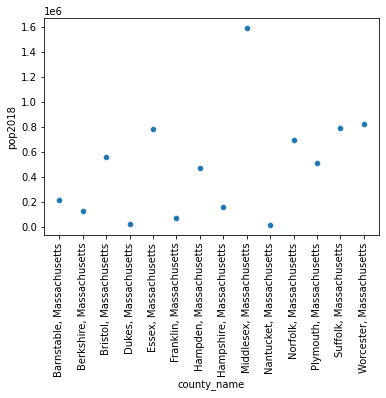

In [12]:
#Massachusetts County and Population Visualization 
sns.scatterplot(x='county_name', y='pop2018', data=df_MA)
plt.xticks(rotation=90)
plt.show()

Depiction of County Civic Engagement Statistics

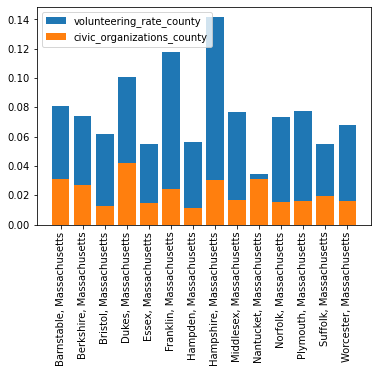

In [13]:
plt.bar(df_MA['county_name'], df_MA['volunteering_rate_county'])
plt.bar(df_MA['county_name'], df_MA['civic_organizations_county'])
plt.legend(['volunteering_rate_county', 'civic_organizations_county'], loc='upper left')
plt.xticks(rotation=90)
plt.show()


                            volunteering_rate_county  \
volunteering_rate_county                    1.000000   
civic_organizations_county                  0.436894   

                            civic_organizations_county  
volunteering_rate_county                      0.436894  
civic_organizations_county                    1.000000  
OLS with a constant (numbers recomputed from social_capital_county.csv; this cell was not re-run):
No. Observations: 14 Massachusetts counties
const = 0.0110, volunteering_rate_county = 0.1438
R-squared = 0.191 (r = 0.437): a weak positive relationship


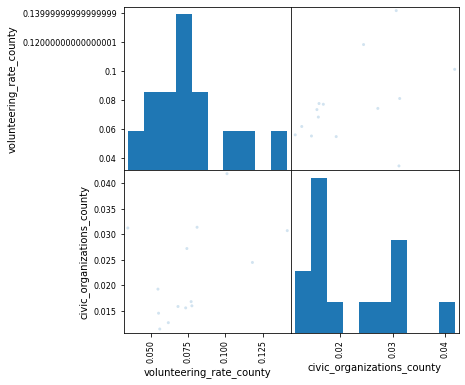

In [14]:
Sum_stats = df_MA[['volunteering_rate_county', 'civic_organizations_county']]
corr = Sum_stats.corr()
print(corr)
scatter_matrix(Sum_stats, alpha=0.2, figsize=(6, 6))
# Added a constant (intercept) term so the regression is not forced through zero
model = sm.OLS(Sum_stats['civic_organizations_county'], sm.add_constant(Sum_stats['volunteering_rate_county'])).fit()
print(model.summary())